In [56]:
# For plotting we include this code
# To visualize call viz_circle.
import math
import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector


# Takes a statevector and a label
class QubitSystem:

  def __init__(
      self,
      statevector: np.ndarray,
      label: str = "Qubit System",
      registers=None,
  ):
    self.label = label
    self.registers = registers  # List of (name, size) tuples
    self.set_statevector(statevector)

  def set_statevector(self, statevector: np.ndarray):
    sv = np.asarray(statevector, dtype=np.complex128).flatten()
    if sv.ndim != 1:
      raise ValueError("Statevector must be 1D.")
    n_states = sv.size
    n_qubits = int(round(math.log2(n_states)))
    if 2**n_qubits != n_states:
      raise ValueError("Length must be a power of 2.")
    norm = np.linalg.norm(sv)
    if norm != 0 and not np.isclose(norm, 1.0):
      sv = sv / norm

    self.n_qubits = n_qubits
    self.n_states = n_states
    self.amps = sv
    self.prob = np.abs(sv) ** 2
    self.phase = np.angle(sv)

  def viz_circle(
      self,
      max_cols: int = 4,
      figsize_scale: float = 2.5,
      threshold: float = 1e-5,
  ):
    # 1. Filter for only the states with non-zero probability
    active_indices = [
        idx for idx in range(self.n_states) if self.prob[idx] > threshold
    ]
    if len(active_indices) == 0:
      print("No active states with amplitude above threshold.")
      return

    # Resolve registers if not explicitly passed
    regs = self.registers
    if not regs:
      if self.n_qubits == 9:
        regs = [("index", 2), ("text", 4), ("pattern", 2), ("flag", 1)]
      elif self.n_qubits == 8:
        regs = [("index", 2), ("text", 4), ("pattern", 2)]
      elif self.n_qubits == 15:
        regs = [("index", 2), ("text", 8), ("pattern", 4), ("flag", 1)]
      elif self.n_qubits == 14:
        regs = [("index", 2), ("text", 8), ("pattern", 4)]

    # Sort active states by index register (lowest bits)
    if regs and any(r[0] == "index" for r in regs):
      idx_size = next(r[1] for r in regs if r[0] == "index")
      active_indices.sort(key=lambda idx: idx % (2**idx_size))
    else:
      active_indices.sort(key=lambda idx: idx % 4)

    num_active = len(active_indices)
    cols = max(1, min(max_cols, num_active))
    rows = int(math.ceil(num_active / cols))

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(cols * figsize_scale, rows * (figsize_scale + 0.2)),
        squeeze=False,
    )

    def format_title(idx: int) -> str:
      b = format(idx, f"0{self.n_qubits}b")
      if not regs:
        return f"|{b}⟩"

      parts = {}
      cursor = 0
      for name, size in reversed(regs):
        parts[name] = b[cursor : cursor + size]
        cursor += size

      title_elements = []
      if "index" in parts:
        title_elements.append(f"|{parts['index']}⟩")
      if "text" in parts:
        title_elements.append(f"|{parts['text'][::-1]}⟩")
      if "pattern" in parts:
        title_elements.append(f"|{parts['pattern'][::-1]}⟩")
      if "flag" in parts:
        title_elements.append(f"|flag={parts['flag']}⟩")
      return "".join(title_elements)

    # 3. Draw each active state
    for i in range(rows * cols):
      r, c = divmod(i, cols)
      ax = axes[r, c]
      ax.set_aspect("equal")
      ax.set_xlim(0, 1)
      ax.set_ylim(0, 1)
      ax.axis("off")

      if i >= num_active:
        ax.set_visible(False)
        continue

      idx = active_indices[i]

      # Outer reference circle
      ax.add_patch(plt.Circle((0.5, 0.5), 0.48, fill=False, lw=1.0, alpha=0.5))

      # Filled disk (area proportional to probability)
      radius = 0.48 * np.sqrt(self.prob[idx])
      ax.add_patch(plt.Circle((0.5, 0.5), radius, alpha=0.25))

      # Phase arrow
      angle = self.phase[idx] + np.pi / 2
      L = 0.45
      x2 = 0.5 + L * np.cos(angle)
      y2 = 0.5 + L * np.sin(angle)
      ax.arrow(
          0.5,
          0.5,
          x2 - 0.5,
          y2 - 0.5,
          head_width=0.03,
          head_length=0.05,
          length_includes_head=True,
      )

      ax.set_title(format_title(idx), fontsize=9)

    fig.suptitle(self.label, fontsize=12)
    plt.tight_layout()
    plt.show()


def plot_state_vector(qc_or_data, label="Statevector"):
  if isinstance(qc_or_data, QuantumCircuit):
    sv_data = Statevector.from_instruction(qc_or_data).data
    reg_info = [(reg.name, reg.size) for reg in qc_or_data.qregs]
    QubitSystem(sv_data, label, registers=reg_info).viz_circle()
  else:
    sv_data = qc_or_data.data if hasattr(qc_or_data, "data") else qc_or_data
    QubitSystem(sv_data, label).viz_circle()

In [57]:
def debug_xor(qc):
    # Ordered oppositely |pattern> |text> |shift>
    sv = Statevector.from_instruction(qc)
    for bitstring, amp in sv.to_dict().items():
        if abs(amp) > 1e-5:
            print("bitstring: ", bitstring)
            print("amp: ", amp)
            pattern_part = bitstring[:2][::-1] # Reverse back so they appear in correct order
            text_part = bitstring[2:6][::-1] # Revser back so they appear in correct order
            shift_part = bitstring[6:8]
            k = int(shift_part, 2)
            print(f"Shift k={k} ({shift_part}): pattern_reg = '{pattern_part}'")

In [58]:
# N is the length of Text pattern
# M is the length of pattern
import math
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.quantum_info import Statevector


text: str = "1011"
pattern: str = "01"

def prepare_input(text: str, pattern: str) -> tuple[QuantumCircuit, QuantumRegister, QuantumRegister, QuantumRegister, QuantumRegister]:
        # T = t0t1t2t3 = 1011
    # t_i <=> q_i,so t0 = q0
    # Paper/logical order: \(t_0,t_1,t_2,t_3\)
    # Qiskit printed ket order: \(q_3,q_2,q_1,q_0\)
    N: int = len(text)
    M: int = len(pattern)
    index_size: int = math.ceil(math.log2(N))

    print("N: ", N)
    print("M: ", M)
    print("i: ", index_size)


    # Index register has n = log2(N) qubits.

    # Text register: N qubits
    # Pattern register: M qubits
    # Index register: log2(N) qubits
    # Text and pattern are prepared as basis states.
    # Only the index register is put into uniform superposition.

    # The goal is to shift the text register using the index register we will create soon.


    index_reg = QuantumRegister(index_size, "index") # |k>
    text_reg = QuantumRegister(N, "text")            # |T>
    pattern_reg = QuantumRegister(M, "pattern")      # |P>

    # Initialize flag_reg helper
    flag_reg = QuantumRegister(1, "flag")

    qc = QuantumCircuit(index_reg, text_reg, pattern_reg, flag_reg)

    # Paper convention: text_reg[i] stores t_i.
    # Qiskit displays basis-state labels as |q_(N-1)...q_0|,
    # so printed bitstrings appear reversed relative to T = t0 t1 ... t_(N-1).
    def transform_text_reg(text):
        for i, bit in enumerate(text):
            if bit == "1":
                qc.x(text_reg[i])
            print("i: ", i)
            print("bit: ", bit)

    def transform_pattern_reg(pattern):
        for i, bit in enumerate(pattern):
            if bit == "1":
                qc.x(pattern_reg[i])
            print("i: ", i)
            print("bit: ", bit)

    print("------------------")
    transform_text_reg(text)
    print("------------------")

    transform_pattern_reg(pattern)

    # Put index register into uniform superposition
    qc.h(index_reg) # 1/2 (|00> + |01> + |10> + |11>) k = 2^0*1 + 2^1*0 = 1
    # |1011> ---> |0111> --> |0111> --> |0111> 
    return qc, index_reg, text_reg, pattern_reg, flag_reg

def verify_hadamard_uniformity(qc: QuantumCircuit, index_reg):
    state = Statevector.from_instruction(qc)

    index_qubits = [qc.find_bit(q).index for q in index_reg]

    print(state.probabilities_dict(qargs=index_qubits))

# Left shifts the qubits of the text register by k positions.
def build_cyclic_shift_operator(index_len, text_len):
    """
    Dynamically shifts text_reg based on the binary value of index_reg.
    Uses visited list to prevent redundant or undoing gates.
    """

    template_qc = QuantumCircuit(index_len + text_len)

    
    for i in range(index_len):
        # Determine the shift distance for this bit position (1, 2, 4, 8...)
        shift_amount = (2**i) % text_len
        if shift_amount == 0: continue
            
        visited = [False] * text_len
        
        for j in range(text_len):
            if not visited[j]:
                current = j
                while True:
                    next_node = (current + shift_amount) % text_len
                    if next_node == j:
                        break
                    
                    template_qc.cswap(i, index_len + current, index_len + next_node) # Must append from index_len offset to end up at text part of circuit. Before we had index_reg[i], text_reg[current], text_reg[next_node]
                    visited[next_node] = True
                    current = next_node
                visited[j] = True

    return template_qc
# But we only want it to happen if k0 = 1
# Note for index_size = 2 such that k = 2k1 + k0 
# This means that if we have 1/2( |00> + |01> + |10> + |11> ) then |01> and |11> has k0 = 1
# So we replace with conditional

# Implement XOR
# After cycle shift all candidate bits are on the first M qubits of the text register.
# We apply the CNOT with each M first qubits between text_reg and pattern_reg
# Then we check if the outcome is 00 for any CNOT 
def apply_xor(qc, text_reg, pattern_reg):
    """Applies the XOR function via controlled NOTs on the pattern register with the text register.
    """
    for i in range(len(pattern_reg)):
        qc.cx(text_reg[i], pattern_reg[i])

In [59]:
def grover_oracle(qc: QuantumCircuit, index_reg: QuantumRegister, text_reg: QuantumRegister, pattern_reg: QuantumRegister, flag_reg: QuantumRegister):

    cyclic_shift_circuit_template = build_cyclic_shift_operator(len(index_reg), len(text_reg))
    qc.compose(cyclic_shift_circuit_template, qubits=list(index_reg) + list(text_reg), inplace=True) # Composes the cyclic shift circuit (that we can inverse later) and stamps it onto our working qc.
    plot_state_vector(Statevector.from_instruction(qc).data, "After applying cyclic shift")

    qc.draw("mpl")
    #print(qc.draw('text', fold=-1))

    apply_xor(qc, text_reg, pattern_reg)
    #print(qc.draw('text', fold=-1))
    debug_xor(qc)

    # Grover Oracle
    # We need to identify exact matches. How do we do that?
    # Since the pattern register is the one being modified, we can simply look to see if the pattern registers are all zero.
    # We must also ensure that no invalid positions are considered correct.
    # The grover oracle is an operator that acts on the pattern register.
    # Its operation is only to flip the sign of state in question.
    qc.draw("mpl")

    # We will apply the toffoli gate.
    # And it will only target the branch whose index is results in |11> after flipping all zeros in the index_register.


    # Initialize flag into |-> state
    print(qc.draw('text', fold=-1))
    qc.x(flag_reg[0]) # |0> --> |1>
    plot_state_vector(Statevector.from_instruction(qc).data, "After applying qc.x(flag_regg[0]).")

    qc.h(flag_reg[0]) # 1/srt(2) (|0> - |1>)
    plot_state_vector(Statevector.from_instruction(qc).data, "After applying qc.h(flag_reg[0]).")

    # Mark state
    qc.x(pattern_reg) # Flips all qubits of all branchs' pattern_register.
    print(qc.draw('text', fold=-1))
    qc.mcx(list(pattern_reg), flag_reg[0]) # Phase kickback, but only the branch with |11> after flip will activate here.
    plot_state_vector(Statevector.from_instruction(qc).data, "After applying toffoli, i.e., |-> to correct branch.")
    qc.x(pattern_reg)  # Flip back the pattern register
    plot_state_vector(Statevector.from_instruction(qc).data, "After restoring pattern registers.")
    # Probabilities are still the same at this point. But before we can probability amplify, we must mark the correct state.

    # Uncompute the flag since it's just noise at this point.
    qc.h(flag_reg[0]) # Double hadamadard yields identity.
    qc.x(flag_reg[0])
    plot_state_vector(Statevector.from_instruction(qc).data, "After uncomputing the flag.")
    print(qc.draw('text', fold=-1))

    # Undo XOR and cyclic shift
    apply_xor(qc, text_reg, pattern_reg)


    qc.compose(cyclic_shift_circuit_template.inverse(), qubits=list(index_reg) + list(text_reg), inplace=True)

    print(qc.draw('text', fold=-1))
    plot_state_vector(Statevector.from_instruction(qc).data, "After restoring undoing XOR and cyclic shifts.")

N:  4
M:  2
i:  2
------------------
i:  0
bit:  1
i:  1
bit:  0
i:  2
bit:  1
i:  3
bit:  1
------------------
i:  0
bit:  0
i:  1
bit:  1
           ┌───┐
  index_0: ┤ H ├
           ├───┤
  index_1: ┤ H ├
           ├───┤
   text_0: ┤ X ├
           └───┘
   text_1: ─────
           ┌───┐
   text_2: ┤ X ├
           ├───┤
   text_3: ┤ X ├
           └───┘
pattern_0: ─────
           ┌───┐
pattern_1: ┤ X ├
           └───┘
     flag: ─────
                


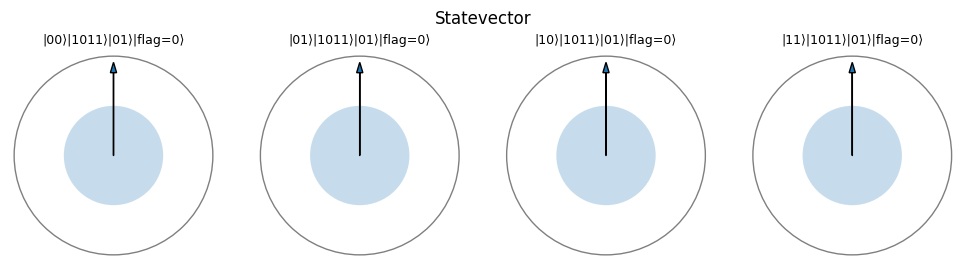

2
---------------------------------------


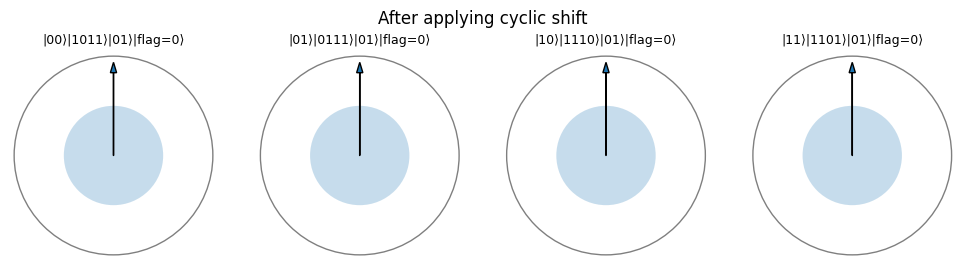

bitstring:  000111001
amp:  (0.4999999999999999+0j)
Shift k=0 (00): pattern_reg = '00'
bitstring:  001011110
amp:  (0.4999999999999999+0j)
Shift k=3 (11): pattern_reg = '00'
bitstring:  001101111
amp:  (0.4999999999999999+0j)
Shift k=3 (11): pattern_reg = '00'
bitstring:  011110100
amp:  (0.4999999999999999+0j)
Shift k=2 (10): pattern_reg = '10'
           ┌───┐                         
  index_0: ┤ H ├─■──■──■─────────────────
           ├───┤ │  │  │                 
  index_1: ┤ H ├─┼──┼──┼──■──■───────────
           ├───┤ │  │  │  │  │           
   text_0: ┤ X ├─X──┼──┼──X──┼───■───────
           └───┘ │  │  │  │  │   │       
   text_1: ──────X──X──┼──┼──X───┼────■──
           ┌───┐    │  │  │  │   │    │  
   text_2: ┤ X ├────X──X──X──┼───┼────┼──
           ├───┤       │     │   │    │  
   text_3: ┤ X ├───────X─────X───┼────┼──
           └───┘               ┌─┴─┐  │  
pattern_0: ────────────────────┤ X ├──┼──
           ┌───┐               └───┘┌─┴─┐
pattern_1: ┤ X ├──────

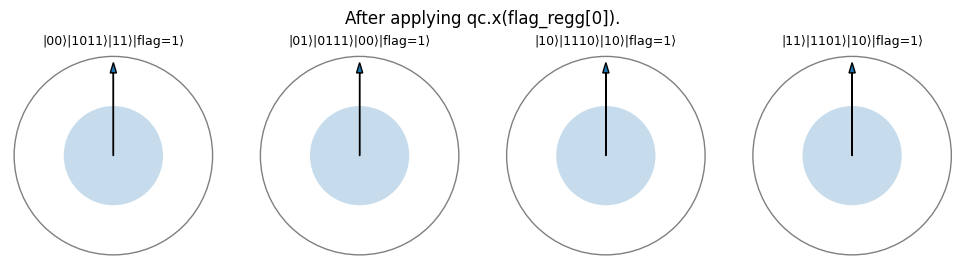

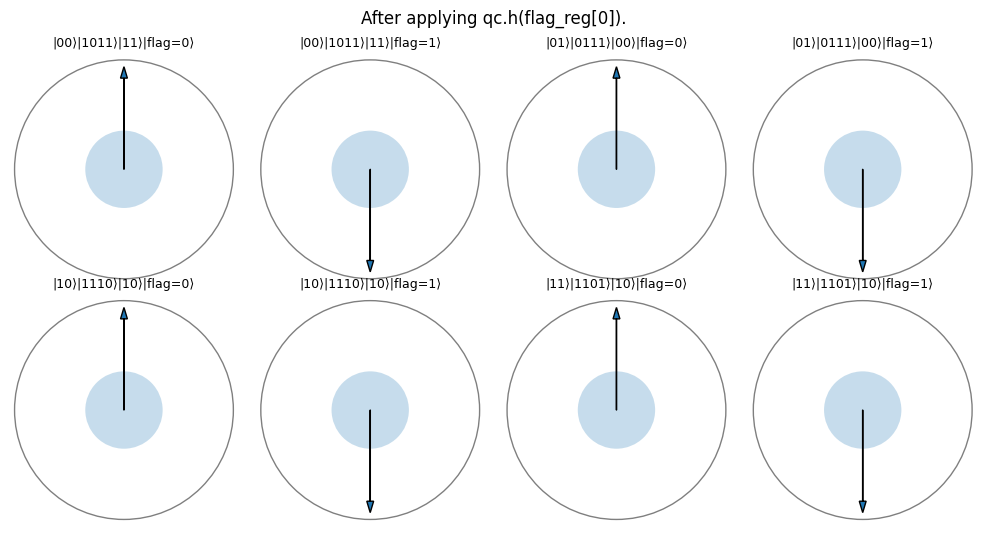

           ┌───┐                                
  index_0: ┤ H ├──■───■──■──────────────────────
           ├───┤  │   │  │                      
  index_1: ┤ H ├──┼───┼──┼──■──■────────────────
           ├───┤  │   │  │  │  │                
   text_0: ┤ X ├──X───┼──┼──X──┼───■────────────
           └───┘  │   │  │  │  │   │            
   text_1: ───────X───X──┼──┼──X───┼────■───────
           ┌───┐      │  │  │  │   │    │       
   text_2: ┤ X ├──────X──X──X──┼───┼────┼───────
           ├───┤         │     │   │    │       
   text_3: ┤ X ├─────────X─────X───┼────┼───────
           └───┘                 ┌─┴─┐  │  ┌───┐
pattern_0: ──────────────────────┤ X ├──┼──┤ X ├
           ┌───┐                 └───┘┌─┴─┐├───┤
pattern_1: ┤ X ├──────────────────────┤ X ├┤ X ├
           ├───┤┌───┐                 └───┘└───┘
     flag: ┤ X ├┤ H ├───────────────────────────
           └───┘└───┘                           


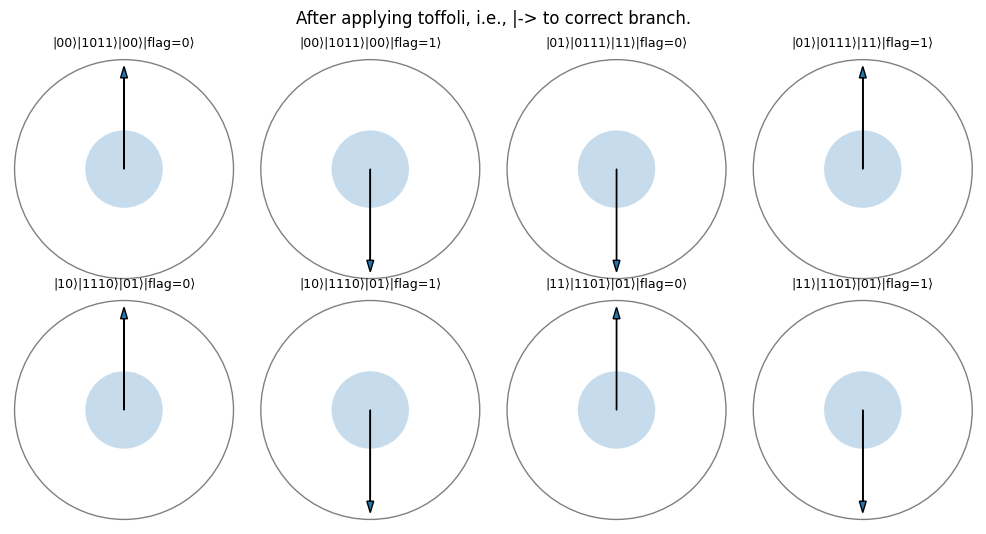

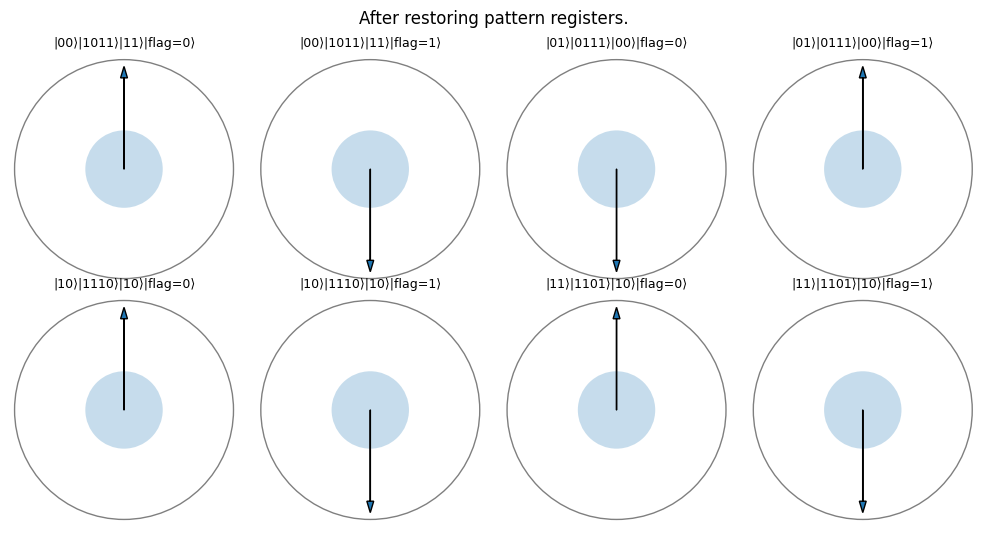

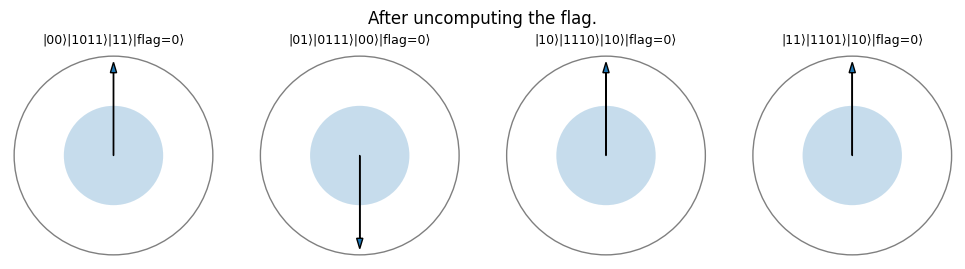

           ┌───┐                                               
  index_0: ┤ H ├──■───■──■─────────────────────────────────────
           ├───┤  │   │  │                                     
  index_1: ┤ H ├──┼───┼──┼──■──■───────────────────────────────
           ├───┤  │   │  │  │  │                               
   text_0: ┤ X ├──X───┼──┼──X──┼───■───────────────────────────
           └───┘  │   │  │  │  │   │                           
   text_1: ───────X───X──┼──┼──X───┼────■──────────────────────
           ┌───┐      │  │  │  │   │    │                      
   text_2: ┤ X ├──────X──X──X──┼───┼────┼──────────────────────
           ├───┤         │     │   │    │                      
   text_3: ┤ X ├─────────X─────X───┼────┼──────────────────────
           └───┘                 ┌─┴─┐  │  ┌───┐     ┌───┐     
pattern_0: ──────────────────────┤ X ├──┼──┤ X ├──■──┤ X ├─────
           ┌───┐                 └───┘┌─┴─┐├───┤  │  ├───┤     
pattern_1: ┤ X ├──────────────────────┤ 

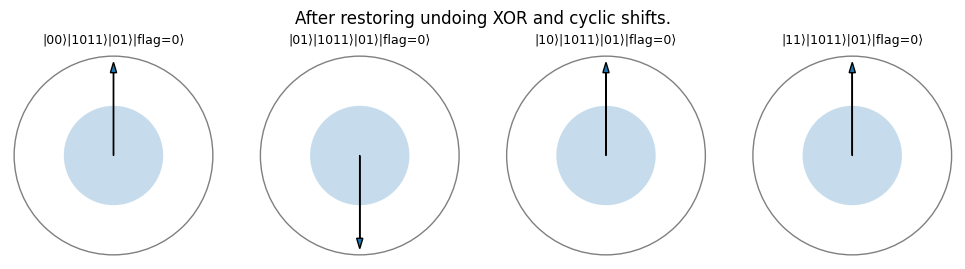

           ┌───┐                                                                   
  index_0: ┤ H ├──■───■──■─────────────────────────────────────────────────■──■──■─
           ├───┤  │   │  │                                                 │  │  │ 
  index_1: ┤ H ├──┼───┼──┼──■──■─────────────────────────────────────■──■──┼──┼──┼─
           ├───┤  │   │  │  │  │                                     │  │  │  │  │ 
   text_0: ┤ X ├──X───┼──┼──X──┼───■────────────────────────■────────┼──X──┼──┼──X─
           └───┘  │   │  │  │  │   │                        │        │  │  │  │  │ 
   text_1: ───────X───X──┼──┼──X───┼────■───────────────────┼────■───X──┼──┼──X──X─
           ┌───┐      │  │  │  │   │    │                   │    │   │  │  │  │    
   text_2: ┤ X ├──────X──X──X──┼───┼────┼───────────────────┼────┼───┼──X──X──X────
           ├───┤         │     │   │    │                   │    │   │     │       
   text_3: ┤ X ├─────────X─────X───┼────┼───────────────────┼────┼───X─────X

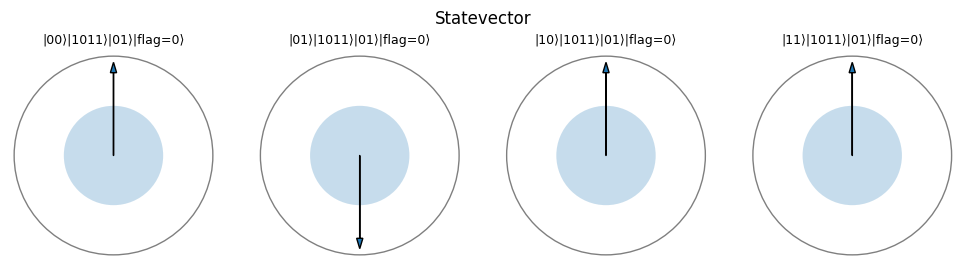

In [ ]:
qc, index_reg, text_reg, pattern_reg, flag_reg = prepare_input(text, pattern)

print(qc.draw('text', fold=-1))
plot_state_vector(Statevector.from_instruction(qc).data)
print(len(index_reg))

# |00>|1011>|01> + |01>|0111>|01> + |10>|1110>|01> + |11>|1101>|01> 
#     |01>             |01>             |01>             |01>
print("---------------------------------------")


grover_oracle(qc, index_reg, text_reg, pattern_reg, flag_reg)
print(qc.draw('text', fold=-1))
plot_state_vector(Statevector.from_instruction(qc).data)

# Grover diffuser
# Right now the oracle has marked the state in question. We need to increase its probability
def apply_diffusion(qc, index_reg):
    qc.h(index_reg)
    qc.x(index_reg)
    
    # Multi-controlled Z reflection
    qc.h(index_reg[-1])
    qc.mcx(list(index_reg[:-1]), index_reg[-1])
    qc.h(index_reg[-1])
    
    qc.x(index_reg)
    qc.h(index_reg)

apply_diffusion(qc, index_reg)
print(qc.draw('text', fold=-1))
plot_state_vector(Statevector.from_instruction(qc).data)

